$${Coutte \;Flow: \; The\; analytical\; solution\; for \;the\; Navier \;Stokes\; Equation \;is\; \frac{dp}{dx} = \mu \frac{d^2u}{dy^2}}$$

In [55]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

In [56]:
H =0.1
x = np.linspace(0,10,500)
y = np.linspace(0,H,500)

X,Y = np.meshgrid(x,y)

In [57]:
# assuming there is no pressure gradient and u(0) = 0 and u(h) = 0.1 m/s 
# therefore the differential equation is now 0 = d2u/dy2

u = np.zeros_like(X)
from scipy.integrate import solve_bvp

# using w as an auxiallary variable, theres now a couple system of differential equations - dw/dy = 0 and du/dy = w 
#z = [u,w]

def eqn(y,z):
    u = z[0]
    w = z[1]

    du_dy = w
    dw_dy = np.zeros_like(y)

    return np.vstack((du_dy, dw_dy))

def boundary_conditions(z0,zh): #these are basically residuals
    return np.array([z0[0],
                     zh[0]-0.2])


z_guess = np.zeros((2,y.size))

sol_coutte = solve_bvp(
    eqn,
    boundary_conditions,
    y,
    z_guess
)



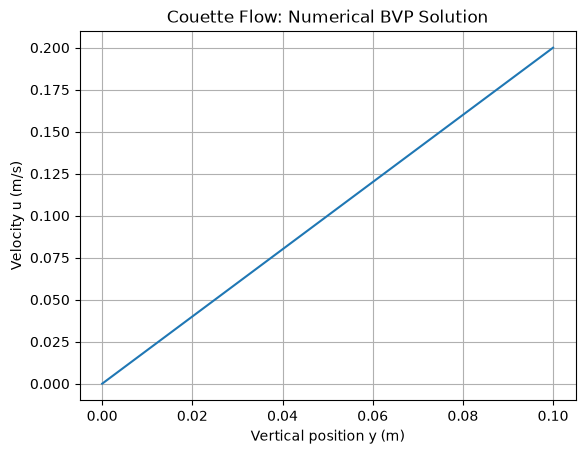

Converged: True
Velocity at bottom: 8.32508255771486e-16 m/s
Velocity at top: 0.2 m/s


In [58]:
u_plot = sol_coutte.sol(y)[0]
plt.plot(y, u_plot)
plt.ylabel("Velocity u (m/s)")
plt.xlabel("Vertical position y (m)")
plt.title("Couette Flow: Numerical BVP Solution")
plt.grid(True)
plt.show()

print("Converged:", sol_coutte.success)
print("Velocity at bottom:", sol_coutte.sol(0)[0], "m/s")
print("Velocity at top:", sol_coutte.sol(H)[0], "m/s")

AI for pretty visualization

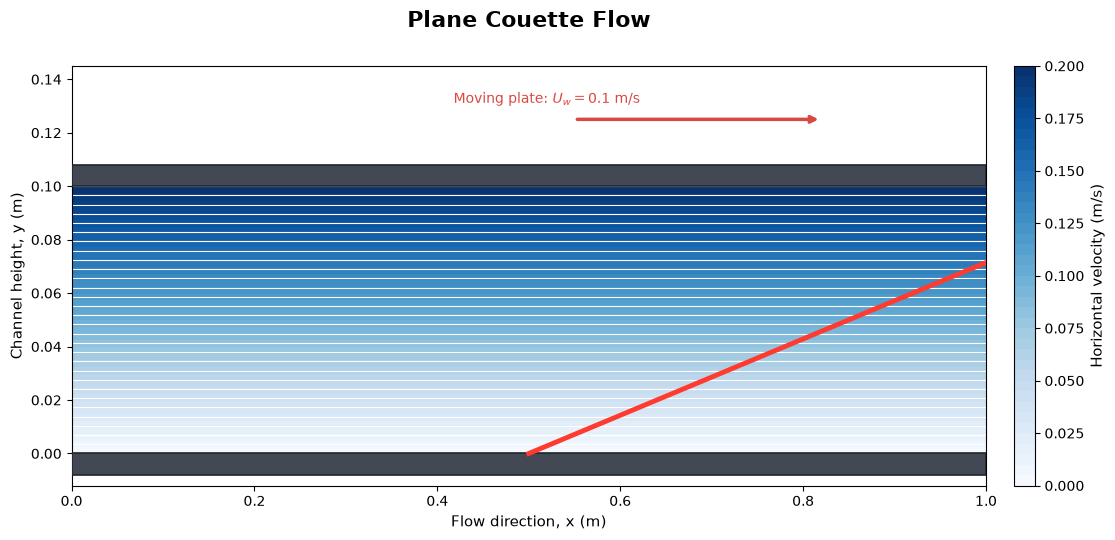

In [59]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


U_wall = 0.1

# Velocity from the numerical BVP solution
u = sol_coutte.sol(Y.ravel())[0].reshape(Y.shape)
v = np.zeros_like(u)

# ----------------------------------
# Create the visualization
# ----------------------------------
fig, ax = plt.subplots(figsize=(12, 5.5))

# Fluid region colored by velocity magnitude
fluid = ax.contourf(
    X, Y, u,
    levels=40,
    cmap="Blues"
)
# Highlight the velocity profile at the channel midpoint
x_profile = 0.5

y_line = np.linspace(0, H, 200)
u_line = sol_coutte.sol(y_line)[0]

# Normalize velocity to the channel width for visualization
x_line = x_profile + 0.35 * (u_line / U_wall)

ax.plot(
    x_line,
    y_line,
    color="#ff3b30",
    linewidth=3.5,
    label="Velocity profile",
    zorder=10
)
# Add subtle streamlines (horizontal for fully developed flow)
ax.streamplot(
    x, y, u, v,
    color="white",
    linewidth=0.8,
    density=(1.2, 1.0),
    arrowsize=1.2
)

# Draw the bottom plate
ax.add_patch(Rectangle(
    (0, -0.008), 1, 0.008,
    facecolor="#424954",
    edgecolor="#20252b",
    linewidth=1.2,
    zorder=5
))

# Draw the moving top plate
ax.add_patch(Rectangle(
    (0, H), 1, 0.008,
    facecolor="#424954",
    edgecolor="#20252b",
    linewidth=1.2,
    zorder=5
))

# Arrow showing the moving upper plate
ax.annotate(
    "",
    xy=(0.82, H + 0.025),
    xytext=(0.55, H + 0.025),
    arrowprops=dict(
        arrowstyle="->",
        color="#d94841",
        lw=2.5
    ),
    annotation_clip=False
)

ax.text(
    0.52, H + 0.031,
    r"Moving plate: $U_w = 0.1$ m/s",
    color="#d94841",
    fontsize=10,
    ha="center",
    clip_on=False
)

# Colorbar
cbar = fig.colorbar(fluid, ax=ax, pad=0.025)
cbar.set_label("Horizontal velocity (m/s)", fontsize=11)

# Labels and formatting
ax.set_title(
    "Plane Couette Flow",
    fontsize=16,
    fontweight="bold",
    pad=28
)
ax.set_xlabel("Flow direction, x (m)", fontsize=11)
ax.set_ylabel("Channel height, y (m)", fontsize=11)

ax.set_xlim(0, 1)
ax.set_ylim(-0.012, H + 0.045)
ax.set_aspect("auto")
ax.grid(False)

plt.tight_layout()
plt.show()


Poiseuille Flow - The analytical solution for the poiseuille flow is also $\frac{dp}{dx} = \mu \frac{d^2u}{dy^2}$ but with different boundary conditions 

In [60]:
#  there is a pressure gradient of -0.1 pa/m and u(0) = 0 and u(h) = 0
# therefore the differential equation is now -10 = mu*d2u/dy2
dp_dx = -0.1
mu = 1e-3
u_poiss = np.zeros_like(X)
from scipy.integrate import solve_bvp



def eqn(y,z):
    u = z[0]
    w = z[1]

    du_dy = w
    dw_dy = np.ones_like(y)*dp_dx/mu 

    return np.vstack((du_dy, dw_dy))

def boundary_conditions(z0,zh):
    return np.array([z0[0],
                     zh[0]])



sol_poise = solve_bvp(
    eqn,
    boundary_conditions,
    y,
    z_guess
)



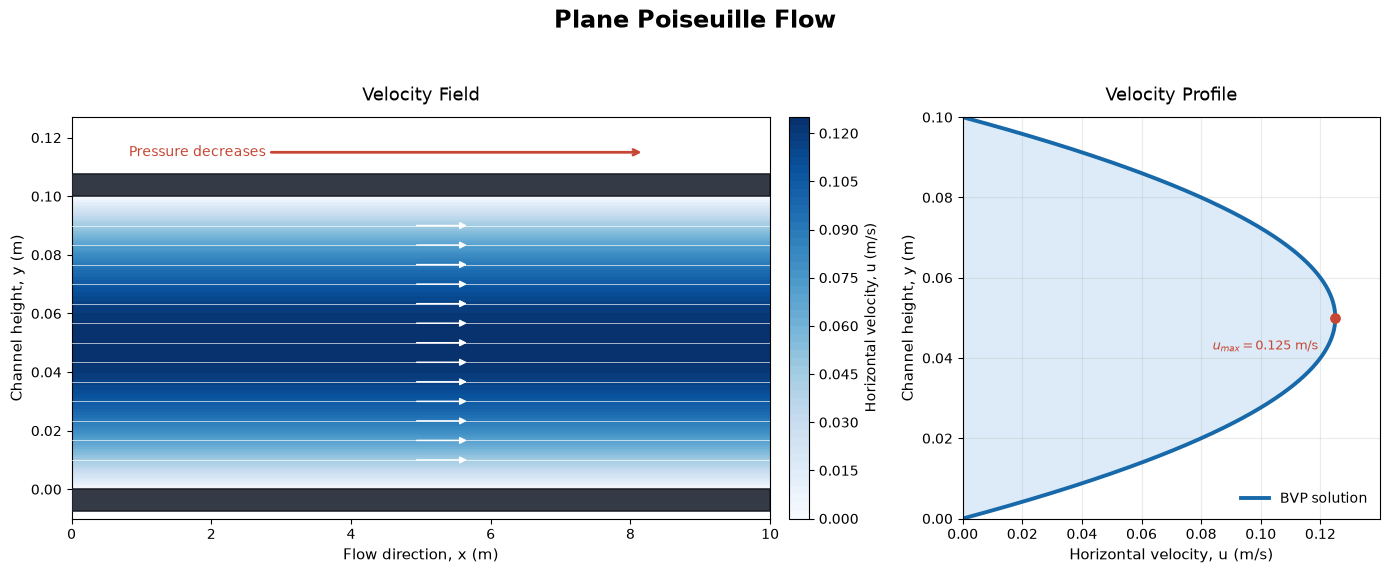

In [61]:

# ==========================================
# Poiseuille Flow:  Visualization
# Reuses x, y, X, Y and sol_poise from above
# ==========================================

from matplotlib.patches import Rectangle

# Evaluate the numerical BVP solution on the existing grid
u_field_poiss = sol_poise.sol(Y.ravel())[0].reshape(Y.shape)

# Velocity profile
u_profile_poiss = sol_poise.sol(y)[0]
u_max_poiss = np.max(u_profile_poiss)

# ==========================================
# Set up the figure
# ==========================================

fig_poiss, (ax_flow_poiss, ax_profile_poiss) = plt.subplots(
    1, 2,
    figsize=(14, 5.8),
    gridspec_kw={"width_ratios": [1.8, 1]}
)

fig_poiss.suptitle(
    "Plane Poiseuille Flow",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

# ==========================================
# LEFT: Fluid between parallel plates
# ==========================================

cf_poiss = ax_flow_poiss.contourf(
    X, Y, u_field_poiss,
    levels=50,
    cmap="Blues"
)

# Horizontal flow lines and uniformly positioned arrows
stream_y_poiss = np.linspace(0.10 * H, 0.90 * H, 13)

for yi_poiss in stream_y_poiss:
    ax_flow_poiss.plot(
        [x[0], x[-1]], [yi_poiss, yi_poiss],
        color="white",
        linewidth=0.65,
        alpha=0.7,
        zorder=3
    )

    ax_flow_poiss.annotate(
        "",
        xy=(0.57 * x[-1], yi_poiss),
        xytext=(0.49 * x[-1], yi_poiss),
        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            lw=1.1,
            mutation_scale=10
        ),
        zorder=4
    )

# Stationary plates
plate_color_poiss = "#343a46"
plate_height_poiss = 0.075 * H
plate_width_poiss = x[-1] - x[0]

ax_flow_poiss.add_patch(Rectangle(
    (x[0], -plate_height_poiss),
    plate_width_poiss, plate_height_poiss,
    facecolor=plate_color_poiss,
    edgecolor="#171b23",
    linewidth=1.1,
    zorder=5
))

ax_flow_poiss.add_patch(Rectangle(
    (x[0], H),
    plate_width_poiss, plate_height_poiss,
    facecolor=plate_color_poiss,
    edgecolor="#171b23",
    linewidth=1.1,
    zorder=5
))

# Pressure-drop annotation
ax_flow_poiss.annotate(
    "Pressure decreases",
    xy=(0.82 * x[-1], H + 0.15 * H),
    xytext=(0.18 * x[-1], H + 0.15 * H),
    ha="center",
    va="center",
    fontsize=10,
    color="#c74634",
    arrowprops=dict(
        arrowstyle="->",
        color="#c74634",
        linewidth=2
    ),
    annotation_clip=False
)

ax_flow_poiss.set_xlim(x[0], x[-1])
ax_flow_poiss.set_ylim(-0.10 * H, H + 0.27 * H)
ax_flow_poiss.set_xlabel("Flow direction, x (m)", fontsize=11)
ax_flow_poiss.set_ylabel("Channel height, y (m)", fontsize=11)
ax_flow_poiss.set_title("Velocity Field", fontsize=13, pad=12)
ax_flow_poiss.grid(False)

cbar_poiss = fig_poiss.colorbar(
    cf_poiss,
    ax=ax_flow_poiss,
    fraction=0.045,
    pad=0.025
)
cbar_poiss.set_label("Horizontal velocity, u (m/s)", fontsize=10)

# ==========================================
# RIGHT: Numerical velocity profile
# ==========================================

ax_profile_poiss.fill_betweenx(
    y,
    0,
    u_profile_poiss,
    color="#62a6dc",
    alpha=0.22
)

ax_profile_poiss.plot(
    u_profile_poiss,
    y,
    color="#1769aa",
    linewidth=2.8,
    label="BVP solution"
)

# Mark maximum velocity
idx_max_poiss = np.argmax(u_profile_poiss)

ax_profile_poiss.scatter(
    u_profile_poiss[idx_max_poiss],
    y[idx_max_poiss],
    color="#c74634",
    s=45,
    zorder=5
)

ax_profile_poiss.annotate(
    rf"$u_{{max}}={u_max_poiss:.3f}$ m/s",
    xy=(u_profile_poiss[idx_max_poiss], y[idx_max_poiss]),
    xytext=(-12, -23),
    textcoords="offset points",
    ha="right",
    fontsize=9,
    color="#c74634"
)

ax_profile_poiss.set_xlabel("Horizontal velocity, u (m/s)", fontsize=11)
ax_profile_poiss.set_ylabel("Channel height, y (m)", fontsize=11)
ax_profile_poiss.set_title("Velocity Profile", fontsize=13, pad=12)
ax_profile_poiss.set_xlim(0, 1.12 * u_max_poiss)
ax_profile_poiss.set_ylim(0, H)
ax_profile_poiss.grid(True, alpha=0.25)
ax_profile_poiss.legend(loc="lower right", frameon=False)

# Final layout
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


In [62]:
# Superposition of Couette and Poiseuille Flow

u_coutte_super = sol_coutte.sol(Y.ravel())[0].reshape(Y.shape)
u_poise_super = sol_poise.sol(Y.ravel())[0].reshape(Y.shape)

u_field_super = u_coutte_super + u_poise_super

# Combined velocity profile
u_profile_super = (
    sol_coutte.sol(y)[0] + sol_poise.sol(y)[0]
)

u_max_super = np.max(u_profile_super)
idx_max_super = np.argmax(u_profile_super)



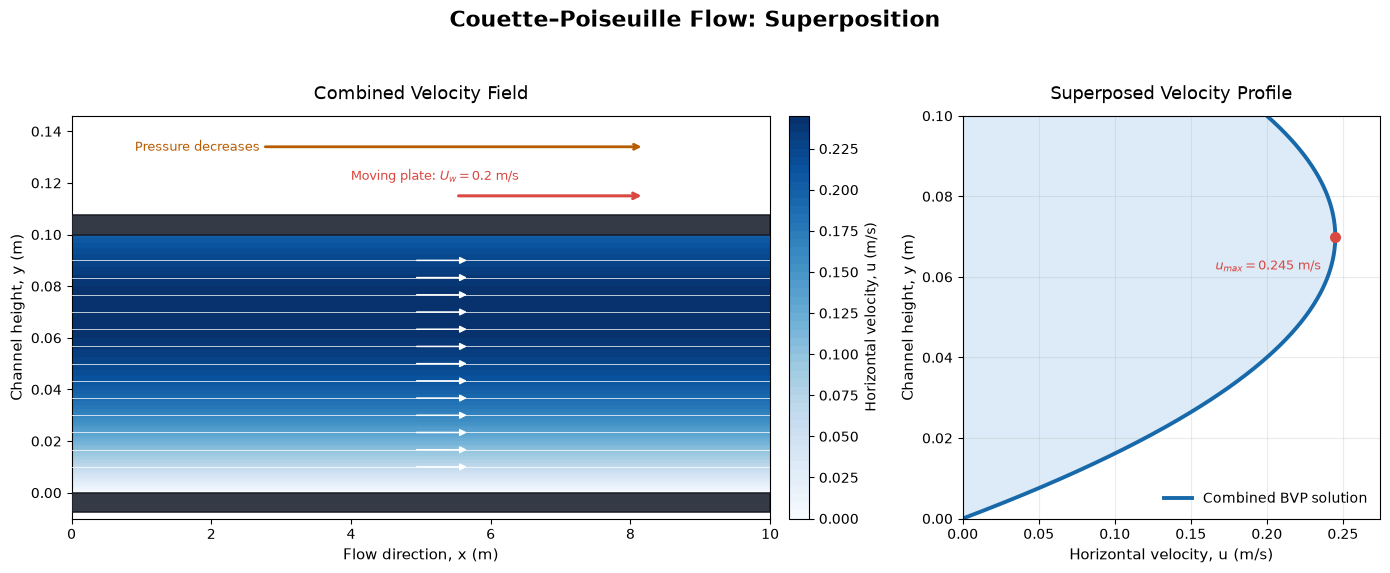

Maximum combined velocity: 0.2450 m/s
Velocity at bottom wall: 0.0000 m/s
Velocity at top wall: 0.2000 m/s


In [64]:
# ==========================================
# 2. Create the figure
# ==========================================

fig_super, (ax_flow_super, ax_profile_super) = plt.subplots(
    1, 2,
    figsize=(14, 5.8),
    gridspec_kw={"width_ratios": [1.8, 1]}
)

fig_super.suptitle(
    "Couette–Poiseuille Flow: Superposition",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

# ==========================================
# LEFT: Combined flow field
# ==========================================

cf_super = ax_flow_super.contourf(
    X, Y, u_field_super,
    levels=50,
    cmap="Blues"
)

# Horizontal flow lines with uniformly spaced arrows
stream_y_super = np.linspace(0.10 * H, 0.90 * H, 13)

for yi_super in stream_y_super:
    ax_flow_super.plot(
        [x[0], x[-1]],
        [yi_super, yi_super],
        color="white",
        linewidth=0.7,
        alpha=0.75,
        zorder=3
    )

    ax_flow_super.annotate(
        "",
        xy=(0.57 * x[-1], yi_super),
        xytext=(0.49 * x[-1], yi_super),
        arrowprops=dict(
            arrowstyle="-|>",
            color="white",
            linewidth=1.1,
            mutation_scale=10
        ),
        zorder=4
    )

# Stationary lower plate
plate_color_super = "#343a46"
plate_height_super = 0.075 * H
plate_width_super = x[-1] - x[0]

ax_flow_super.add_patch(Rectangle(
    (x[0], -plate_height_super),
    plate_width_super,
    plate_height_super,
    facecolor=plate_color_super,
    edgecolor="#171b23",
    linewidth=1.1,
    zorder=5
))

# Moving upper plate
ax_flow_super.add_patch(Rectangle(
    (x[0], H),
    plate_width_super,
    plate_height_super,
    facecolor=plate_color_super,
    edgecolor="#171b23",
    linewidth=1.1,
    zorder=5
))

# Upper plate motion
ax_flow_super.annotate(
    "",
    xy=(0.82 * x[-1], H + 0.15 * H),
    xytext=(0.55 * x[-1], H + 0.15 * H),
    arrowprops=dict(
        arrowstyle="->",
        color="#d94841",
        linewidth=2.2
    ),
    annotation_clip=False
)

ax_flow_super.text(
    0.52 * x[-1],
    H + 0.21 * H,
    r"Moving plate: $U_w=0.2$ m/s",
    color="#d94841",
    fontsize=9,
    ha="center"
)

# Pressure gradient annotation
ax_flow_super.annotate(
    "Pressure decreases",
    xy=(0.82 * x[-1], H + 0.34 * H),
    xytext=(0.18 * x[-1], H + 0.34 * H),
    ha="center",
    va="center",
    fontsize=9,
    color="#b85c00",
    arrowprops=dict(
        arrowstyle="->",
        color="#b85c00",
        linewidth=2
    ),
    annotation_clip=False
)

# Flow-field formatting
ax_flow_super.set_xlim(x[0], x[-1])
ax_flow_super.set_ylim(
    -0.10 * H,
    H + 0.46 * H
)

ax_flow_super.set_xlabel("Flow direction, x (m)", fontsize=11)
ax_flow_super.set_ylabel("Channel height, y (m)", fontsize=11)
ax_flow_super.set_title("Combined Velocity Field", fontsize=13, pad=12)
ax_flow_super.grid(False)

cbar_super = fig_super.colorbar(
    cf_super,
    ax=ax_flow_super,
    fraction=0.045,
    pad=0.025
)
cbar_super.set_label("Horizontal velocity, u (m/s)", fontsize=10)

# ==========================================
# RIGHT: Combined velocity profile
# ==========================================

ax_profile_super.fill_betweenx(
    y,
    0,
    u_profile_super,
    color="#62a6dc",
    alpha=0.22
)

ax_profile_super.plot(
    u_profile_super,
    y,
    color="#1769aa",
    linewidth=2.8,
    label="Combined BVP solution"
)

# Mark the maximum velocity
ax_profile_super.scatter(
    u_profile_super[idx_max_super],
    y[idx_max_super],
    color="#d94841",
    s=48,
    zorder=5
)

ax_profile_super.annotate(
    rf"$u_{{max}}={u_max_super:.3f}$ m/s",
    xy=(
        u_profile_super[idx_max_super],
        y[idx_max_super]
    ),
    xytext=(-10, -24),
    textcoords="offset points",
    ha="right",
    fontsize=9,
    color="#d94841"
)

ax_profile_super.set_xlabel("Horizontal velocity, u (m/s)", fontsize=11)
ax_profile_super.set_ylabel("Channel height, y (m)", fontsize=11)
ax_profile_super.set_title("Superposed Velocity Profile", fontsize=13, pad=12)

ax_profile_super.set_xlim(0, 1.12 * u_max_super)
ax_profile_super.set_ylim(0, H)
ax_profile_super.grid(True, alpha=0.25)
ax_profile_super.legend(loc="lower right", frameon=False)

# ==========================================
# 3. Final layout
# ==========================================

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

print(f"Maximum combined velocity: {u_max_super:.4f} m/s")
print(f"Velocity at bottom wall: {u_profile_super[0]:.4f} m/s")
print(f"Velocity at top wall: {u_profile_super[-1]:.4f} m/s")
